# Case Study 2 - Component analysis: 12 PCW versus 17 PCW

This notebook is the analysis companion to **`4-Component_selection.ipynb`**. It uses the exact candidate-network, observation, biological-seed, and Clingo output filenames written by that notebook. It compares independently selected conventional T-cell regulatory components at **12 PCW** and **17 PCW**. 

## 0. Input files and setup

In [20]:
from pathlib import Path
import hashlib
import json
import re

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display

RESULTS = Path('../Results')
DATA = Path('../Data')
SELECTION = RESULTS / 'Component_selection_Tcell_manual'
OUT = RESULTS / 'Component_analysis_Tcell_12w_vs_17w'
OUT.mkdir(parents=True, exist_ok=True)

WEEKS = ('12w', '17w')
LABELS = {'12w': '12 PCW', '17w': '17 PCW'}
FILES = {
    week: {
        'log': SELECTION / week / 'clingo_optimization.log',
        'sif': SELECTION / week / 'candidate_human_DoRothEA.sif',
        'observations': SELECTION / week / 'candidate_state_observations.csv',
        'candidate_genes': SELECTION / week / 'candidate_genes.csv',
        'seeds': SELECTION / week / 'biological_seeds.csv',
        'seed_ranking': SELECTION / f'{week}_seed_ranking.csv',
        'script': SELECTION / week / f'select_components_{week}.sh',
    }
    for week in WEEKS
}
MSIGDB_GMT = DATA / 'msigdb.v2025.1.Hs.symbols.gmt'


MANUAL_DYNAMICS = {
    '12w': {
        'root': 'S3',
        'fixed_points': ['S4'],
        'positive_reachability': [
            ('S3', 'S0'), ('S0', 'S2'), ('S2', 'S4'),
            ('S3', 'S6'), ('S0', 'S1'), ('S3', 'S7'),
        ],
        'not_imposed': [('S2', 'S5')],
        'main_route': ['S3', 'S0', 'S2', 'S4'],
    },
    '17w': {
        'root': 'S3',
        'fixed_points': ['S4'],
        'positive_reachability': [
            ('S3', 'S0'), ('S0', 'S1'), ('S3', 'S5'), ('S3', 'S4'),
        ],
        'not_imposed': [('S0', 'S2')],
        'main_route': ['S3', 'S4'],
    },
}

for week in WEEKS:
    for key in ('log', 'sif', 'observations', 'candidate_genes', 'seeds', 'seed_ranking'):
        if not FILES[week][key].is_file():
            raise FileNotFoundError(
                f'{LABELS[week]}: missing {key}: {FILES[week][key]}\n'
                'Run 4-Component_selection.ipynb and the Clingo optimization first.'
            )
    script = FILES[week]['script']
    if script.is_file() and FILES[week]['log'].stat().st_mtime < script.stat().st_mtime:
        raise RuntimeError(
            f'{week}: Clingo log is older than the selection script. '
            'Rerun the selection optimizer to avoid analyzing outdated dynamics.'
        )
print('Analysis output:', OUT.resolve())

Analysis output: /home/eren/Eren_run/Case_study_2/Results/Component_analysis_Tcell_12w_vs_17w


## 1. Read the proven-optimal solution for each week


In [21]:
def read_optimum(path):
    text = path.read_text(encoding='utf-8', errors='replace')
    pattern = re.compile(
        r'(?ms)^Answer:\s*(\d+)[^\n]*\n(.*?)^Optimization:\s*(-?\d+)\s+(-?\d+)\s*$',
    )

    answers = []
    for match in pattern.finditer(text):
        atoms = match.group(2)
        selected = set(re.findall(r'\bnode\("([^"\n]+)"\)', atoms))
        constants = set(re.findall(r'\bstrong_constant\("([^"\n]+)"\)', atoms))
        scores = (-int(match.group(3)), -int(match.group(4)))

        # Intermediate solutions can have zero selected genes.
        answers.append({
            'id': int(match.group(1)),
            'selected': selected,
            'constants': constants,
            'nonconstant': selected - constants,
            'objective': scores,
            'valid_subset': constants <= selected,
            'counts_match_objective': (len(selected), len(constants)) == scores,
        })

    headers = len(re.findall(r'(?m)^Answer:\s*\d+', text))
    if not answers or len(answers) != headers:
        raise RuntimeError(f'{path}: no complete, unambiguous Clingo answers')
    if len({a['id'] for a in answers}) != len(answers):
        raise ValueError(f'{path}: repeated answer IDs; is this a combined log?')
    if not re.search(r'(?im)^\s*OPTIMUM FOUND\s*$|^\s*Optimum\s*:\s*yes\s*$', text):
        raise RuntimeError(f'{path}: optimizer has not proved OPTIMUM FOUND')

    chosen = answers[-1]
    # Strict validation belongs to the *proven optimum*, not early answers.
    if not chosen['selected']:
        raise ValueError(
            f'{path}: final optimum has no node(...) genes. '
            'Check the final Answer block in the Clingo log.'
        )
    if not chosen['valid_subset']:
        unexpected = sorted(chosen['constants'] - chosen['selected'])
        raise ValueError(
            f'{path}: final answer has strong_constant genes outside node(...): '
            f'{unexpected[:10]}. Please inspect the final Clingo answer.'
        )
    if not chosen['counts_match_objective']:
        raise ValueError(
            f'{path}: final Clingo score {chosen["objective"]} does not match '
            f'parsed counts {(len(chosen["selected"]), len(chosen["constants"]))}. '
            'Inspect the final answer and Optimization line.'
        )
    if any(a['objective'] > chosen['objective'] for a in answers):
        raise RuntimeError(f'{path}: an earlier answer has a better objective')
    return chosen, answers


optima, solver_audit = {}, []
for week in WEEKS:
    optima[week], intermediate = read_optimum(FILES[week]['log'])
    for answer in intermediate:
        solver_audit.append({
            'week': week,
            'answer_id': answer['id'],
            'selected_genes': len(answer['selected']),
            'strong_constants': len(answer['constants']),
            'valid_subset': answer['valid_subset'],
            'counts_match_objective': answer['counts_match_objective'],
            'final_proven_optimum': answer['id'] == optima[week]['id'],
        })
    print(f"{LABELS[week]}: answer {optima[week]['id']}, "
          f"{len(optima[week]['selected'])} selected genes, "
          f"{len(optima[week]['constants'])} strong constants")

pd.DataFrame(solver_audit).to_csv(OUT / 'clingo_objective_audit.csv', index=False)

12 PCW: answer 806, 146 selected genes, 104 strong constants
17 PCW: answer 931, 149 selected genes, 111 strong constants


## 2. Load the candidate GRNs and binarized STREAM states

In [22]:
def load_sif(path):
    df = pd.read_csv(path, sep=r'\s+', header=None, comment='#', dtype=str)
    if df.shape[1] != 3:
        raise ValueError(f'{path}: expected source, sign, target columns')
    df.columns = ['source', 'sign', 'target']
    for col in ('source', 'target'):
        df[col] = df[col].str.strip().str.upper()
    df['sign'] = df['sign'].str.strip()
    if not df.sign.isin(['1', '-1']).all():
        raise ValueError(f'{path}: regulatory signs must be 1 or -1')
    return df.drop_duplicates().reset_index(drop=True)


def load_observations(path):
    df = pd.read_csv(path, dtype=str, keep_default_na=False, index_col=0)
    df.index = df.index.astype(str).str.strip()
    df.columns = df.columns.astype(str).str.strip().str.upper()
    if df.index.duplicated().any() or df.columns.duplicated().any():
        raise ValueError(f'{path}: duplicate state or gene identifiers')
    df = df.apply(lambda col: col.str.strip().str.upper())
    df = df.replace({'ND': np.nan, 'NA': np.nan, 'NAN': np.nan, '': np.nan})
    df = df.apply(pd.to_numeric, errors='raise')
    valid = df.isna() | df.isin([0, 1])
    if not valid.to_numpy().all():
        raise ValueError(f'{path}: state values must be 0, 1 or ND')
    return df.astype(float)


def read_gene_list(path):
    frame = pd.read_csv(path, dtype=str)
    if 'gene' not in frame.columns:
        raise ValueError(f'{path}: missing gene column')
    genes = frame['gene'].dropna().str.strip().str.upper()
    return set(genes[genes.ne('')])

candidate, obs = {}, {}
observation_audit = []
input_genes, seeds, seed_ranking = {}, {}, {}
for week in WEEKS:
    candidate[week] = load_sif(FILES[week]['sif'])
    obs[week] = load_observations(FILES[week]['observations'])
    input_genes[week] = read_gene_list(FILES[week]['candidate_genes'])
    seeds[week] = read_gene_list(FILES[week]['seeds'])
    seed_ranking[week] = pd.read_csv(FILES[week]['seed_ranking'])
    expected_genes = set(candidate[week].source) | set(candidate[week].target)
    if input_genes[week] != expected_genes:
        raise ValueError(f'{week}: candidate_genes.csv does not match the signed SIF')
    # Genes not determined in any state are omitted from the selection export.
    unexpected = set(obs[week].columns) - input_genes[week]
    if unexpected:
        raise ValueError(
            f'{week}: observation CSV contains {len(unexpected)} genes outside '
            f'the candidate SIF, e.g. {sorted(unexpected)[:10]}'
        )
    missing = input_genes[week] - set(obs[week].columns)
    # Reintroduce absent genes as all-ND, without assigning invented 0/1 calls.
    obs[week] = obs[week].reindex(columns=sorted(input_genes[week]))
    for gene in sorted(missing):
        observation_audit.append({
            'week': week, 'gene': gene,
            'status': 'not_exported_all_ND',
        })
    print(f'{week}: restored {len(missing)} all-ND gene columns '
          'omitted from the sparse observation CSV')
    if not set(MANUAL_DYNAMICS[week]['fixed_points']).issubset(obs[week].index):
        raise ValueError(f'{week}: the required S4 fixed-point observation is missing')
    if MANUAL_DYNAMICS[week]['root'] not in obs[week].index:
        raise ValueError(f'{week}: manual root S3 is missing')
    for a, b in MANUAL_DYNAMICS[week]['positive_reachability']:
        if a not in obs[week].index or b not in obs[week].index:
            raise ValueError(f'{week}: manual dynamical route {a} → {b} missing')
    print(f'{LABELS[week]}: {len(obs[week])} states, '
          f'{len(input_genes[week])} candidate genes, '
          f'{len(candidate[week])} signed candidate edges, '
          f'{len(seeds[week])} biological seeds')

pd.DataFrame(observation_audit, columns=['week', 'gene', 'status']).to_csv(
    OUT / 'all_ND_candidate_gene_audit.csv', index=False
)

# These constraints were manually written in the attached selection notebook.
# This table is a record of them, not a new Boolean inference step.
dynamics_rows = []
for week, spec in MANUAL_DYNAMICS.items():
    for a, b in spec['positive_reachability']:
        dynamics_rows.append({'week': week, 'constraint': 'reachability',
                              'from_state': a, 'to_state': b})
    for fixed in spec['fixed_points']:
        dynamics_rows.append({'week': week, 'constraint': 'fixed_point',
                              'from_state': fixed, 'to_state': fixed})
manual_constraints = pd.DataFrame(dynamics_rows)
manual_constraints.to_csv(OUT / 'manual_constraints_from_component_selection.csv', index=False)
display(manual_constraints)

12w: restored 91 all-ND gene columns omitted from the sparse observation CSV
12 PCW: 8 states, 150 candidate genes, 843 signed candidate edges, 32 biological seeds
17w: restored 93 all-ND gene columns omitted from the sparse observation CSV
17 PCW: 6 states, 150 candidate genes, 863 signed candidate edges, 31 biological seeds


,week,constraint,from_state,to_state
0,12w,reachability,S3,S0
1,12w,reachability,S0,S2
2,12w,reachability,S2,S4
3,12w,reachability,S3,S6
4,12w,reachability,S0,S1
5,12w,reachability,S3,S7
6,12w,fixed_point,S4,S4
7,17w,reachability,S3,S0
8,17w,reachability,S0,S1
9,17w,reachability,S3,S5


### 2.1. Compare the biological seeds and candidate networks

`4-Component_selection.ipynb` selects human T-cell gene-set/marker seeds separately for each week, expands them through DoRothEA neighbors and short paths, and caps each network at 150 candidate genes. We first compare these **input domains**, because differences in which genes were eligible strongly affect all later component comparisons.

In [23]:
from itertools import chain

seed_rows = []
for category, sets in [('biological_seeds', seeds), ('candidate_domain', input_genes)]:
    a, b = sets['12w'], sets['17w']
    seed_rows.append({
        'level': category, '12w': len(a), '17w': len(b),
        'shared': len(a & b), '12w_only': len(a - b),
        '17w_only': len(b - a),
        'jaccard': len(a & b) / len(a | b) if a | b else np.nan,
    })
seed_domain_summary = pd.DataFrame(seed_rows)
seed_domain_summary.to_csv(OUT / 'biological_seed_and_candidate_overlap.csv', index=False)
display(seed_domain_summary)

pd.DataFrame([
    {'gene': gene,
     '12w_seed': gene in seeds['12w'], '17w_seed': gene in seeds['17w'],
     '12w_candidate': gene in input_genes['12w'],
     '17w_candidate': gene in input_genes['17w']}
    for gene in sorted(input_genes['12w'] | input_genes['17w'] |
                       seeds['12w'] | seeds['17w'])
]).to_csv(OUT / 'seed_and_candidate_membership_by_week.csv', index=False)

for week in WEEKS:
    ranks = seed_ranking[week]
    print(f'{LABELS[week]} — selected seeds in ranking table: '
          f'{int(ranks.chosen_seed.sum()) if "chosen_seed" in ranks else "unknown"}')


,level,12w,17w,shared,12w_only,17w_only,jaccard
0,biological_seeds,32,31,26,6,5,0.702703
1,candidate_domain,150,150,129,21,21,0.754386


12 PCW — selected seeds in ranking table: 32
17 PCW — selected seeds in ranking table: 31


## 3. Extract the optimal nonconstant network and its largest SCC

Remove the genes classified as **strong constants** by BoNesis, then retain the largest *strongly connected component* (SCC), following the original notebook. Export the selected, nonconstant and core gene sets for each week.

In [24]:
results = {}
for week in WEEKS:
    chosen = optima[week]
    edges = candidate[week]
    eligible = set(edges.source) | set(edges.target)
    if chosen['selected'] - eligible:
        raise ValueError(f'{week}: selected genes missing from the candidate SIF')

    nonconstant = set(chosen['nonconstant'])
    graph = nx.DiGraph()
    graph.add_nodes_from(nonconstant)
    graph.add_edges_from(zip(edges.source, edges.target))
    graph = graph.subgraph(nonconstant).copy()
    sccs = sorted(nx.strongly_connected_components(graph),
                  key=lambda s: (-len(s), tuple(sorted(s))))
    if not sccs:
        raise ValueError(f'{week}: no nonconstant SCC')
    core = set(sccs[0])

    nonconstant_edges = edges[edges.source.isin(nonconstant) &
                               edges.target.isin(nonconstant)].copy()
    core_edges = edges[edges.source.isin(core) & edges.target.isin(core)].copy()
    week_out = OUT / week
    week_out.mkdir(parents=True, exist_ok=True)
    for filename, genes in [('selected_genes', chosen['selected']),
                            ('strong_constants', chosen['constants']),
                            ('nonconstant_genes', nonconstant), ('core_genes', core)]:
        (week_out / f'{filename}.txt').write_text('\n'.join(sorted(genes)) + '\n')
    nonconstant_edges.to_csv(week_out / 'synthesis_nonconstant_network.sif',
                             sep='\t', header=False, index=False)
    core_edges.to_csv(week_out / 'synthesis_core_network.sif',
                      sep='\t', header=False, index=False)

    results[week] = {
        'selected': chosen['selected'], 'constants': chosen['constants'],
        'nonconstant': nonconstant, 'core': core,
        'candidate_genes': eligible,
        'nonconstant_edges': nonconstant_edges, 'core_edges': core_edges,
        'n_scc': len(sccs),
    }
    print(f'{LABELS[week]}: {len(chosen["selected"])} selected → '
          f'{len(nonconstant)} nonconstant → {len(core)} core genes; '
          f'{len(core_edges)} signed core regulations')

# This reduction identifies a regulatory core; it does not itself recheck BoNesis dynamics.

12 PCW: 146 selected → 42 nonconstant → 8 core genes; 21 signed core regulations
17 PCW: 149 selected → 38 nonconstant → 10 core genes; 24 signed core regulations


## 4. Compare gene sets between 12 PCW and 17 PCW

Calculate overlap and Jaccard similarity for the **selected**, **nonconstant**, and **largest-SCC** genes.

In [25]:
rows = []
for level in ('selected', 'nonconstant', 'core'):
    a, b = results['12w'][level], results['17w'][level]
    shared = a & b
    rows.append({
        'set': level, '12w_genes': len(a), '17w_genes': len(b),
        'shared': len(shared), '12w_only': len(a - b), '17w_only': len(b - a),
        'jaccard': len(shared) / len(a | b) if a | b else np.nan,
        'percent_12w_shared': 100 * len(shared) / len(a) if a else np.nan,
        'percent_17w_shared': 100 * len(shared) / len(b) if b else np.nan,
        'shared_genes': '; '.join(sorted(shared)),
    })
    for filename, genes in [('shared', shared), ('12w_only', a - b),
                            ('17w_only', b - a)]:
        (OUT / f'{level}_{filename}.txt').write_text('\n'.join(sorted(genes)) + '\n')

overlap = pd.DataFrame(rows)
overlap.to_csv(OUT / 'gene_set_overlap_12w_vs_17w.csv', index=False)
display(overlap.drop(columns='shared_genes'))

common_domain = results['12w']['candidate_genes'] & results['17w']['candidate_genes']
core12, core17 = results['12w']['core'], results['17w']['core']
eligibility = pd.DataFrame([
    {'week': '12w', 'core_only_genes': len(core12 - core17),
     'also_eligible_at_other_week': len((core12 - core17) & results['17w']['candidate_genes']),
     'not_in_other_candidate_domain': len((core12 - core17) - results['17w']['candidate_genes'])},
    {'week': '17w', 'core_only_genes': len(core17 - core12),
     'also_eligible_at_other_week': len((core17 - core12) & results['12w']['candidate_genes']),
     'not_in_other_candidate_domain': len((core17 - core12) - results['12w']['candidate_genes'])},
])
eligibility.to_csv(OUT / 'core_gene_eligibility_audit.csv', index=False)
display(eligibility)

pd.DataFrame([
    {'gene': g, '12w_candidate': g in results['12w']['candidate_genes'],
     '17w_candidate': g in results['17w']['candidate_genes'],
     '12w_selected': g in results['12w']['selected'],
     '17w_selected': g in results['17w']['selected'],
     '12w_core': g in core12, '17w_core': g in core17}
    for g in sorted(results['12w']['candidate_genes'] |
                    results['17w']['candidate_genes'])
]).to_csv(OUT / 'gene_selection_status_by_week.csv', index=False)

,set,12w_genes,17w_genes,shared,12w_only,17w_only,jaccard,percent_12w_shared,percent_17w_shared
0,selected,146,149,125,21,24,0.735294,85.616438,83.892617
1,nonconstant,42,38,28,14,10,0.538462,66.666667,73.684211
2,core,8,10,5,3,5,0.384615,62.500000,50.000000


,week,core_only_genes,also_eligible_at_other_week,not_in_other_candidate_domain
0,12w,3,3,0
1,17w,5,5,0


### Gene overlap figure

The bars show the two week-specific sets and their intersection. The Jaccard index summarizes similarity without assuming that the networks have the same size.

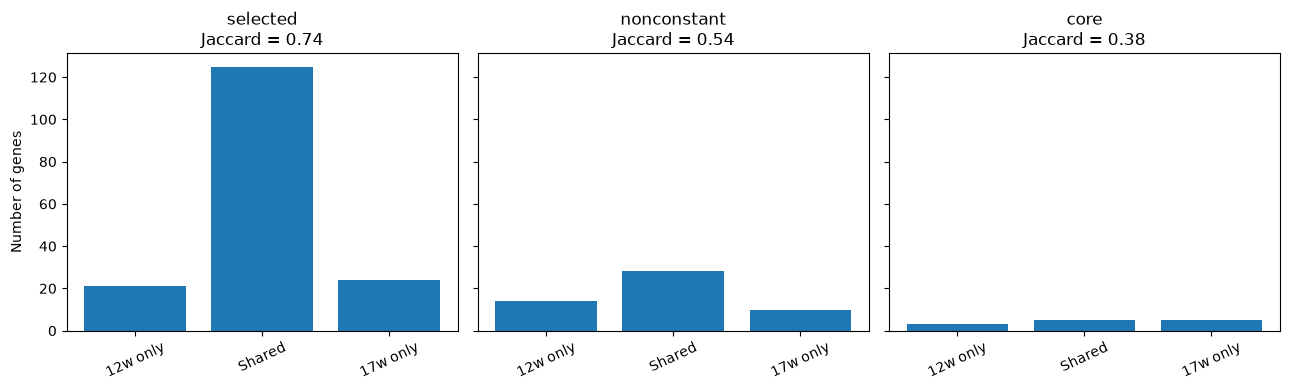

In [26]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (_, dat) in zip(axs, overlap.iterrows()):
    ax.bar(['12w only', 'Shared', '17w only'],
           [dat['12w_only'], dat['shared'], dat['17w_only']])
    ax.set_title(f'{dat["set"]}\nJaccard = {dat["jaccard"]:.2f}')
    ax.tick_params(axis='x', labelrotation=25)
axs[0].set_ylabel('Number of genes')
fig.tight_layout()
fig.savefig(OUT / 'gene_overlap_summary.png', dpi=180)
plt.show()

In [9]:
graphs = {}
network_rows, degrees = [], []
for week in WEEKS:
    graph = nx.DiGraph()
    graph.add_nodes_from(results[week]['core'])
    graph.add_edges_from(zip(results[week]['core_edges'].source,
                             results[week]['core_edges'].target))
    graphs[week] = graph
    frame = results[week]['core_edges']
    network_rows.append({
        'week': week, 'genes': len(graph), 'directed_edges': graph.number_of_edges(),
        'signed_edges': len(frame), 'activations': int((frame.sign == '1').sum()),
        'inhibitions': int((frame.sign == '-1').sum()),
        'density': nx.density(graph),
        'mean_in_degree': float(np.mean([d for _, d in graph.in_degree()])),
        'mean_out_degree': float(np.mean([d for _, d in graph.out_degree()])),
        'max_in_degree': max((d for _, d in graph.in_degree()), default=0),
        'max_out_degree': max((d for _, d in graph.out_degree()), default=0),
    })
    for gene in sorted(graph):
        degrees.append({
            'week': week, 'gene': gene, 'in_degree': graph.in_degree(gene),
            'out_degree': graph.out_degree(gene), 'total_degree': graph.degree(gene),
            'in_both_cores': gene in (core12 & core17),
        })

network_stats = pd.DataFrame(network_rows)
gene_degrees = pd.DataFrame(degrees)
network_stats.to_csv(OUT / 'network_statistics_12w_17w.csv', index=False)
gene_degrees.to_csv(OUT / 'gene_degrees_12w_17w.csv', index=False)
display(network_stats)
for week in WEEKS:
    print(f'{LABELS[week]} — highest-degree core genes')
    display(gene_degrees[gene_degrees.week == week]
            .sort_values(['total_degree', 'gene'], ascending=[False, True]).head(12))

,week,genes,directed_edges,signed_edges,activations,inhibitions,density,mean_in_degree,mean_out_degree,max_in_degree,max_out_degree
0,12w,8,21,21,20,1,0.375000,2.625,2.625,3,4
1,17w,10,24,24,19,5,0.266667,2.400,2.400,5,4


12 PCW — highest-degree core genes


,week,gene,in_degree,out_degree,total_degree,in_both_cores
1,12w,ETS1,3,4,7,True
4,12w,GATA3,3,3,6,True
6,12w,RUNX1,3,3,6,True
7,12w,STAT3,3,3,6,True
2,12w,FOS,2,3,5,False
5,12w,MYC,3,2,5,False
3,12w,FOXP1,3,1,4,True
0,12w,E2F1,1,2,3,False


17 PCW — highest-degree core genes


,week,gene,in_degree,out_degree,total_degree,in_both_cores
13,17w,RUNX1,5,3,8,True
16,17w,TP53,4,4,8,False
15,17w,STAT3,3,4,7,True
9,17w,ETS1,2,3,5,True
10,17w,FOXP1,3,2,5,True
11,17w,GATA3,1,3,4,True
14,17w,STAT1,3,1,4,False
12,17w,IRF1,1,2,3,False
8,17w,AR,1,1,2,False
17,17w,ZEB1,1,1,2,False


### Degree distribution

This figure compares connectivity within each reconstructed core, rather than measuring true changes in regulatory activity.

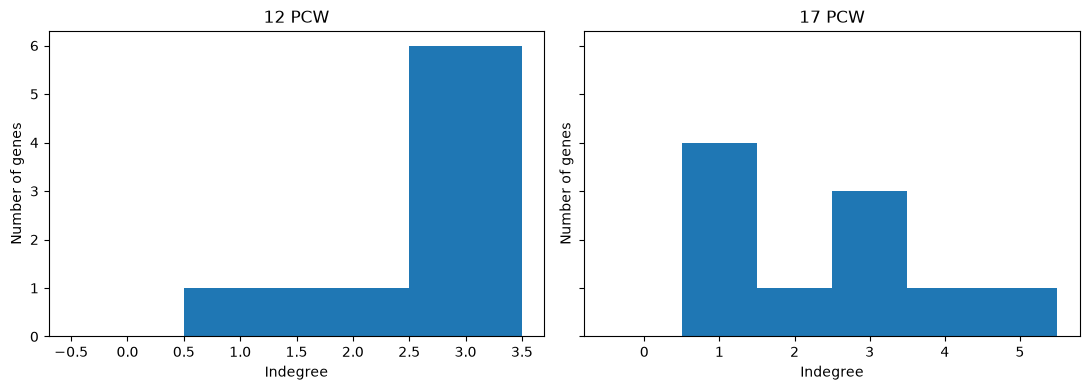

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, week in zip(axs, WEEKS):
    values = [deg for _, deg in graphs[week].in_degree()]
    bins = np.arange(max(values, default=0) + 2) - 0.5
    ax.hist(values, bins=bins)
    ax.set(title=LABELS[week], xlabel='Indegree', ylabel='Number of genes')
fig.tight_layout()
fig.savefig(OUT / 'indegree_12w_vs_17w.png', dpi=180)
plt.show()

## 5. Visualize both signed regulatory cores

Place shared genes at the **same coordinates in both panels** using a common layout. Solid green edges represent activation; dashed orange edges represent inhibition. Gene labels prioritize the most connected genes so the figure remains readable.

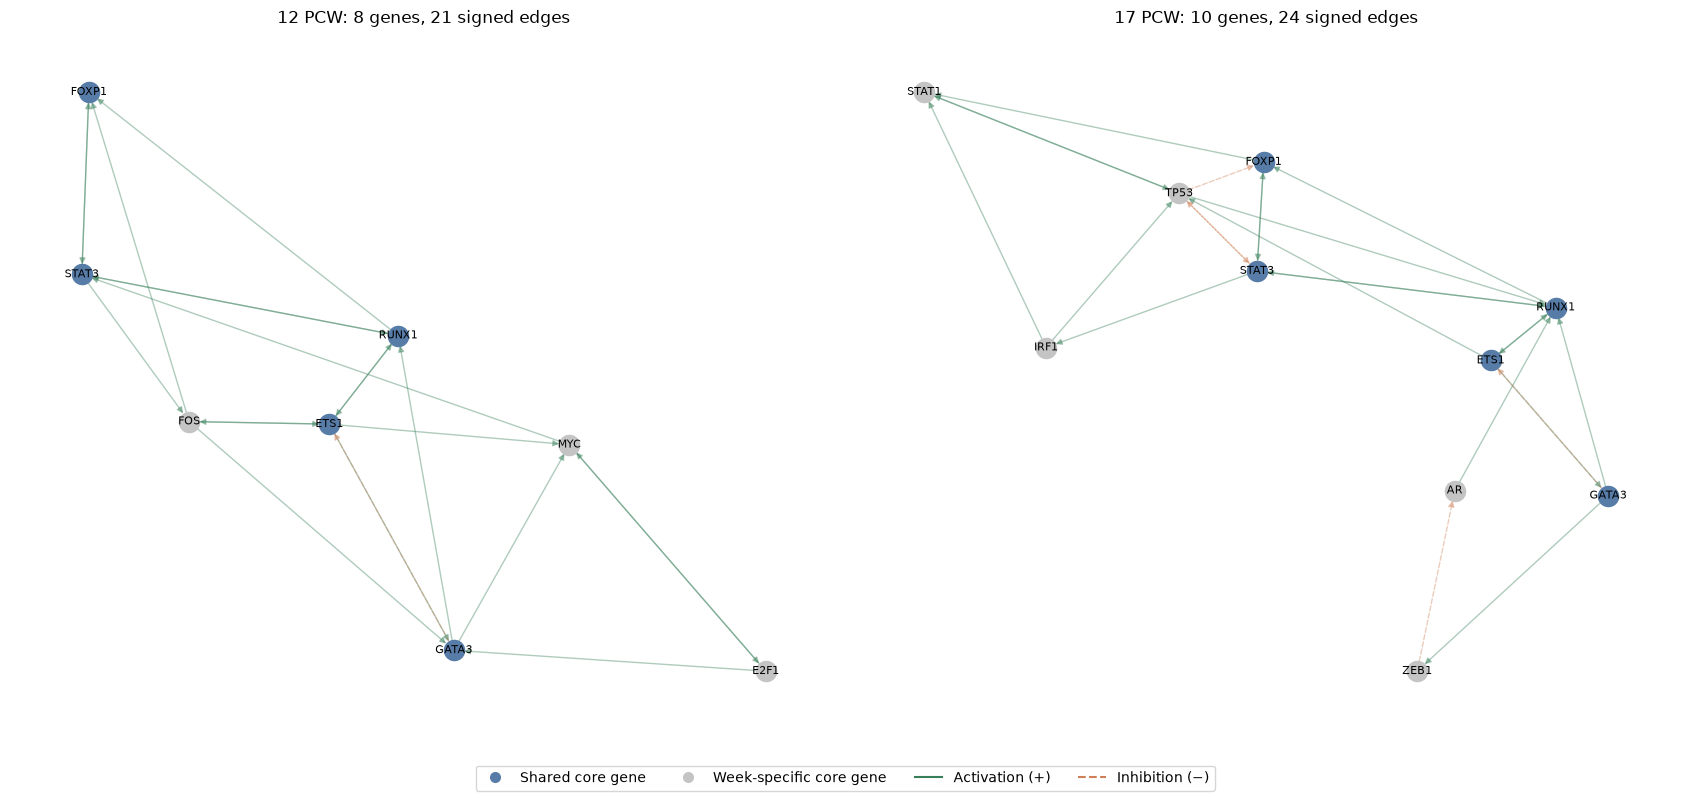

In [27]:
from matplotlib.lines import Line2D

combined = nx.compose(graphs['12w'], graphs['17w'])
layout = nx.spring_layout(combined, seed=42) if len(combined) else {}
shared = core12 & core17
fig, axs = plt.subplots(1, 2, figsize=(17, 8))
for ax, week in zip(axs, WEEKS):
    graph = graphs[week]
    frame = results[week]['core_edges']
    local_shared = sorted(set(graph) & shared)
    local_only = sorted(set(graph) - shared)
    nx.draw_networkx_nodes(graph, layout, nodelist=local_shared,
                           node_color='#577ca8', node_size=210, ax=ax)
    nx.draw_networkx_nodes(graph, layout, nodelist=local_only,
                           node_color='#c4c4c4', node_size=210, ax=ax)
    for sign, color, style in [('1', '#377f59', 'solid'), ('-1', '#cf8058', 'dashed')]:
        subset = frame[frame.sign == sign]
        nx.draw_networkx_edges(graph, layout,
            edgelist=list(zip(subset.source, subset.target)),
            edge_color=color, style=style, alpha=0.40, arrowsize=9,
            node_size=210, width=1, ax=ax)
    ranked = sorted(graph, key=lambda g: (-graph.degree(g), g))
    labels = {gene: gene for gene in ranked[:min(15, len(ranked))]}
    nx.draw_networkx_labels(graph, layout, labels=labels, font_size=8, ax=ax)
    ax.set_title(f'{LABELS[week]}: {len(graph)} genes, {len(frame)} signed edges')
    ax.axis('off')
fig.legend(handles=[
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#577ca8', markersize=9, label='Shared core gene'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#c4c4c4', markersize=9, label='Week-specific core gene'),
    Line2D([0], [0], color='#377f59', label='Activation (+)'),
    Line2D([0], [0], color='#cf8058', linestyle='--', label='Inhibition (−)'),
], loc='lower center', ncol=4)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(OUT / 'signed_core_networks_12w_17w.png', dpi=180)
plt.show()

,week,state,n_core_genes_measured,off,on,ND,determined_fraction
0,12w,S0,8,6,1,1,0.875
1,12w,S1,8,7,0,1,0.875
2,12w,S2,8,7,0,1,0.875
3,12w,S3,8,6,1,1,0.875
4,12w,S4,8,4,3,1,0.875
5,12w,S5,8,7,0,1,0.875
6,12w,S6,8,4,3,1,0.875
7,12w,S7,8,1,6,1,0.875
8,17w,S0,10,7,2,1,0.900
9,17w,S1,10,9,0,1,0.900


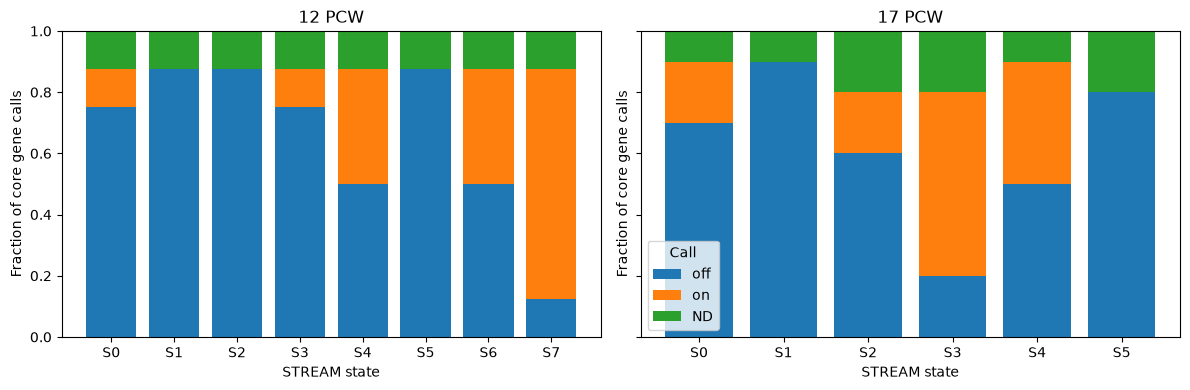

In [12]:
state_rows = []
for week in WEEKS:
    genes = sorted(results[week]['core'] & set(obs[week].columns))
    for state, row in obs[week][genes].iterrows():
        count_off = int((row == 0).sum())
        count_on = int((row == 1).sum())
        n_nd = int(row.isna().sum())
        state_rows.append({
            'week': week, 'state': state, 'n_core_genes_measured': len(genes),
            'off': count_off, 'on': count_on, 'ND': n_nd,
            'determined_fraction': (count_off + count_on) / len(genes) if genes else np.nan,
        })
state_coverage = pd.DataFrame(state_rows)
state_coverage.to_csv(OUT / 'state_binary_coverage.csv', index=False)
display(state_coverage)

fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, week in zip(axs, WEEKS):
    sub = state_coverage[state_coverage.week == week].copy()
    sub = sub.sort_values('state', key=lambda s: s.str.extract(r'(\d+)', expand=False).astype(int))
    bottom = np.zeros(len(sub))
    for label in ('off', 'on', 'ND'):
        ax.bar(sub.state, sub[label] / sub.n_core_genes_measured.replace(0, np.nan),
               bottom=bottom, label=label)
        bottom += (sub[label] / sub.n_core_genes_measured.replace(0, np.nan)).fillna(0).to_numpy()
    ax.set(title=LABELS[week], xlabel='STREAM state', ylabel='Fraction of core gene calls', ylim=(0, 1))
axs[1].legend(title='Call')
fig.tight_layout()
fig.savefig(OUT / 'state_binary_coverage.png', dpi=180)
plt.show()

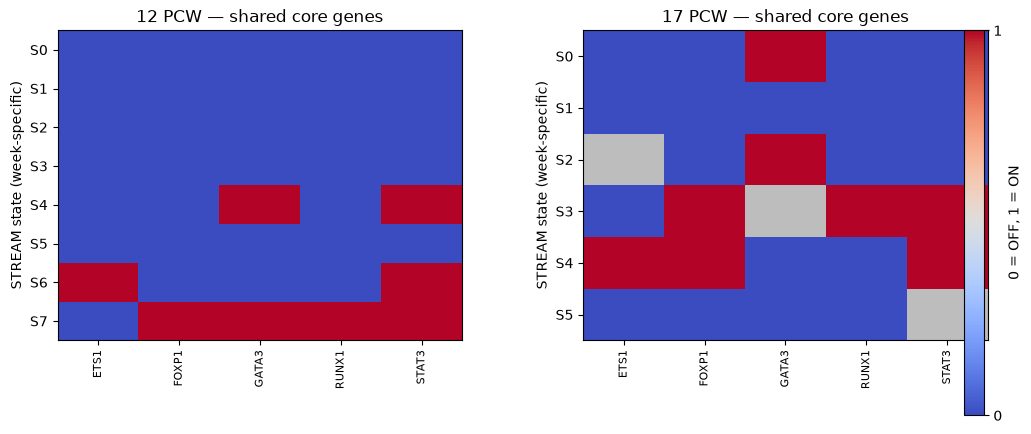

In [13]:
shared_genes = sorted(core12 & core17)
if not shared_genes:
    print('No genes occur in both cores; shared-gene heatmaps are not applicable.')
else:
    fig, axs = plt.subplots(1, 2, figsize=(max(12, len(shared_genes) * .4), 5),
                            sharex=True)
    color_map = plt.get_cmap('coolwarm').copy()
    color_map.set_bad('#bdbdbd')
    for ax, week in zip(axs, WEEKS):
        available = [g for g in shared_genes if g in obs[week]]
        states = sorted(obs[week].index,
                        key=lambda s: int(re.search(r'\d+', s).group()))
        values = obs[week].reindex(index=states, columns=shared_genes).to_numpy(dtype=float)
        im = ax.imshow(np.ma.masked_invalid(values), cmap=color_map, vmin=0, vmax=1, aspect='auto')
        ax.set_yticks(range(len(states)), states)
        ax.set_xticks(range(len(shared_genes)), shared_genes, rotation=90, fontsize=8)
        ax.set_title(f'{LABELS[week]} — shared core genes')
        ax.set_ylabel('STREAM state (week-specific)')
    fig.colorbar(im, ax=axs.tolist(), ticks=[0, 1], label='0 = OFF, 1 = ON', fraction=.025, pad=.04)
    fig.subplots_adjust(bottom=.26, right=.9, wspace=.3)
    fig.savefig(OUT / 'shared_core_binary_profiles.png', dpi=180, bbox_inches='tight')
    plt.show()

### T-cell differentiation markers from Park et al. (2020)

Check whether the study's marker genes are measurable and retained in each candidate, optimal selection, and SCC. These genes are **biological annotation anchors**, not alternative regulatory models. A missing marker may simply lie outside the DoRothEA candidate domain.

In [14]:
# Park et al., Fig. 2D–G: early DN, DP, TCR recombination, and SP markers.
park_markers = {
    'ST18': 'Early DN', 'AQP3': 'DP', 'TOX2': 'DP-to-SP',
    'CD4': 'CD4 lineage', 'CD8A': 'CD8 lineage', 'CD8B': 'CD8 lineage',
    'CCR9': 'αβT entry', 'CDK1': 'Cell cycle',
    'RAG1': 'TCR recombination', 'RAG2': 'TCR recombination',
    'PTCRA': 'Pre-TCR',
}
marker_rows = []
for gene, stage in park_markers.items():
    for week in WEEKS:
        marker_rows.append({
            'gene': gene, 'biological_context': stage, 'week': week,
            'in_candidate': gene in results[week]['candidate_genes'],
            'in_selected': gene in results[week]['selected'],
            'in_nonconstant': gene in results[week]['nonconstant'],
            'in_core': gene in results[week]['core'],
        })
marker_status = pd.DataFrame(marker_rows)
marker_status.to_csv(OUT / 'Park_Tcell_marker_selection_status.csv', index=False)
display(marker_status.pivot(index=['gene', 'biological_context'],
                            columns='week', values='in_core'))

,week,12w,17w
gene,biological_context,,
AQP3,DP,False,False
CCR9,αβT entry,False,False
CD4,CD4 lineage,False,False
CD8A,CD8 lineage,False,False
CD8B,CD8 lineage,False,False
CDK1,Cell cycle,False,False
PTCRA,Pre-TCR,False,False
RAG1,TCR recombination,False,False
RAG2,TCR recombination,False,False


In [15]:
change_rows = []
for week in WEEKS:
    spec = MANUAL_DYNAMICS[week]
    genes = sorted(results[week]['core'] & set(obs[week].columns))
    for start, end in spec['positive_reachability']:
        if start not in obs[week].index or end not in obs[week].index:
            raise ValueError(f'{week}: unknown manually specified state {start} or {end}')
        first = obs[week].loc[start, genes]
        second = obs[week].loc[end, genes]
        determined = first.notna() & second.notna()
        change_rows.append({
            'week': week, 'from_state': start, 'to_state': end,
            'both_determined': int(determined.sum()),
            'off_to_on': int(((first == 0) & (second == 1)).sum()),
            'on_to_off': int(((first == 1) & (second == 0)).sum()),
            'unchanged': int(((first == second) & determined).sum()),
            'undetermined_pair': len(genes) - int(determined.sum()),
            'genes_off_to_on': '; '.join(sorted(g for g in genes if first[g] == 0 and second[g] == 1)),
            'genes_on_to_off': '; '.join(sorted(g for g in genes if first[g] == 1 and second[g] == 0)),
        })
route_changes = pd.DataFrame(change_rows)
route_changes.to_csv(OUT / 'manual_route_binary_differences.csv', index=False)
if not route_changes.empty:
    display(route_changes.drop(columns=['genes_off_to_on', 'genes_on_to_off']))

,week,from_state,to_state,both_determined,off_to_on,on_to_off,unchanged,undetermined_pair
0,12w,S3,S0,7,1,1,5,1
1,12w,S0,S2,7,0,1,6,1
2,12w,S2,S4,7,3,0,4,1
3,12w,S3,S6,7,3,1,3,1
4,12w,S0,S1,7,0,1,6,1
5,12w,S3,S7,7,5,0,2,1
6,17w,S3,S0,8,0,5,3,2
7,17w,S0,S1,9,0,2,7,1
8,17w,S3,S5,7,0,5,2,3
9,17w,S3,S4,8,2,4,2,2


### 9.1. Compare gene-state changes from the root (S3) to fixed point (S4)

The **root S3** and required **S4 fixed point** play the same *modeling roles* in both week-specific problems, even though their cell mixtures and graph topology differ. For each gene available in **both candidate domains**, classify its root-to-S4 change (`0→1`, `1→0`, unchanged, or undetermined). This offers an interpretable cross-week summary without pairing intermediate S-numbers or pretending the samples track the same individual cells.

,week,0→1,1→0,unchanged,undetermined
0,12w,7,10,31,81
1,17w,7,16,24,82


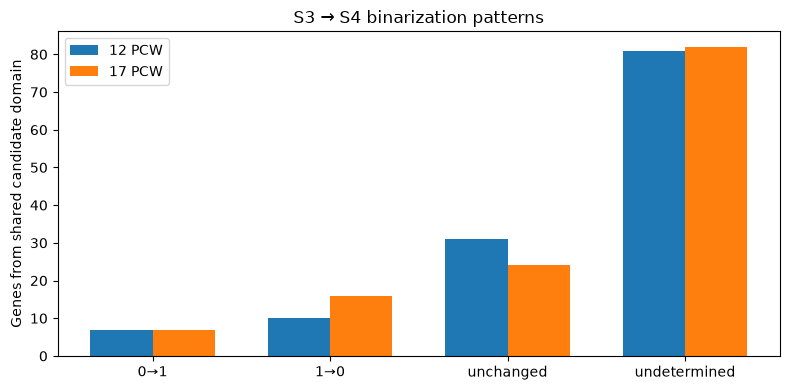

Genes with the same determined change in both weeks: 9


,gene,12w_S3_to_S4,17w_S3_to_S4,12w_selected,12w_core,17w_selected,17w_core
8,BCL2L1,1→0,1→0,True,False,True,False
19,CD28,0→1,0→1,True,False,True,False
21,CD44,0→1,0→1,True,False,True,False
28,CDK6,1→0,1→0,True,False,True,False
75,IRF1,1→0,1→0,True,False,True,True
94,RAG1,1→0,1→0,True,False,True,False
95,RAG2,1→0,1→0,True,False,True,False
125,YY1,1→0,1→0,True,False,True,False
127,ZFP36L1,0→1,0→1,True,False,True,False


In [16]:
root_shift = {}
for week in WEEKS:
    frame = obs[week].loc[['S3', 'S4'], sorted(common_domain)]
    root, final = frame.loc['S3'], frame.loc['S4']
    shift = pd.Series('ND', index=frame.columns, dtype=str)
    both = root.notna() & final.notna()
    shift.loc[both & (root == 0) & (final == 1)] = '0→1'
    shift.loc[both & (root == 1) & (final == 0)] = '1→0'
    shift.loc[both & (root == final)] = 'unchanged'
    root_shift[week] = shift

root_table = pd.DataFrame({
    'gene': sorted(common_domain),
    '12w_S3_to_S4': root_shift['12w'].loc[sorted(common_domain)].values,
    '17w_S3_to_S4': root_shift['17w'].loc[sorted(common_domain)].values,
})
for week in WEEKS:
    root_table[f'{week}_selected'] = root_table.gene.isin(results[week]['selected'])
    root_table[f'{week}_core'] = root_table.gene.isin(results[week]['core'])
root_table.to_csv(OUT / 'common_gene_root_to_S4_binary_changes.csv', index=False)

shift_counts = pd.DataFrame([
    {'week': week, '0→1': (root_shift[week] == '0→1').sum(),
     '1→0': (root_shift[week] == '1→0').sum(),
     'unchanged': (root_shift[week] == 'unchanged').sum(),
     'undetermined': (root_shift[week] == 'ND').sum()}
    for week in WEEKS
])
shift_counts.to_csv(OUT / 'root_to_S4_shift_counts.csv', index=False)
display(shift_counts)

categories = ['0→1', '1→0', 'unchanged', 'undetermined']
fig, ax = plt.subplots(figsize=(8, 4))
xx = np.arange(len(categories))
for idx, week in enumerate(WEEKS):
    vals = shift_counts.loc[shift_counts.week == week, categories].iloc[0].to_numpy()
    ax.bar(xx + (idx - 0.5)*0.35, vals, width=0.35, label=LABELS[week])
ax.set_xticks(xx, categories)
ax.set_ylabel('Genes from shared candidate domain')
ax.set_title('S3 → S4 binarization patterns')
ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'root_to_S4_binary_changes.png', dpi=170, bbox_inches='tight')
plt.show()

consistent = root_table.loc[
    root_table['12w_S3_to_S4'].eq(root_table['17w_S3_to_S4']) &
    root_table['12w_S3_to_S4'].isin(['0→1','1→0'])
]
print('Genes with the same determined change in both weeks:', len(consistent))
display(consistent.head(20))

In [17]:
from scipy.stats import hypergeom
from statsmodels.stats.multitest import multipletests


def load_gobp(path):
    terms = {}
    with path.open(encoding='utf-8') as handle:
        for line in handle:
            fields = line.rstrip('\n').split('\t')
            if len(fields) >= 3 and fields[0].upper().startswith('GOBP_'):
                terms[fields[0]] = {gene.upper() for gene in fields[2:] if gene.strip()}
    return terms

if not MSIGDB_GMT.is_file():
    print('GO analysis skipped: human MSigDB GMT missing:', MSIGDB_GMT)
    go_results = pd.DataFrame()
else:
    terms = load_gobp(MSIGDB_GMT)
    annotated = set().union(*terms.values()) if terms else set()
    background = common_domain & annotated
    print('Common candidate genes:', len(common_domain),
          '; GO-annotated common universe:', len(background))
    if len(background) < 5:
        print('GO analysis skipped: too few common, GO-annotated eligible genes.')
        go_results = pd.DataFrame()
    else:
        all_rows = []
        for week in WEEKS:
            selected = results[week]['core'] & background
            if not selected:
                print(LABELS[week], 'has no core genes in the common background.')
                continue
            local_rows = []
            for term, genes in terms.items():
                members = genes & background
                if len(members) < 5 or len(members) == len(background):
                    continue
                hits = selected & members
                p = float(hypergeom.sf(len(hits) - 1, len(background),
                                       len(members), len(selected)))
                local_rows.append({
                    'week': week, 'go_term': term, 'n_universe': len(background),
                    'n_core_in_universe': len(selected),
                    'n_term_in_universe': len(members), 'n_hits': len(hits),
                    'genes': '; '.join(sorted(hits)), 'pvalue': p,
                })
            if local_rows:
                adjusted = multipletests([x['pvalue'] for x in local_rows],
                                          method='fdr_bh')[1]
                for rec, fdr in zip(local_rows, adjusted):
                    rec['fdr'] = float(fdr)
                all_rows.extend(local_rows)
        go_results = pd.DataFrame(all_rows)
        go_results.to_csv(OUT / 'GO_BP_common_background.csv', index=False)
        if not go_results.empty:
            for week in WEEKS:
                print(f'\n{LABELS[week]}: most enriched GO:BP terms (exploratory)')
                display(go_results[(go_results.week == week) &
                                   (go_results.n_hits >= 2)]
                        .nsmallest(12, 'fdr')[['go_term', 'n_hits', 'fdr', 'genes']])

Common candidate genes: 129 ; GO-annotated common universe: 128

12 PCW: most enriched GO:BP terms (exploratory)


,go_term,n_hits,fdr,genes
368,GOBP_MYELOID_CELL_DIFFERENTIATION,7,0.443141,ETS1; FOS; FOXP1; GATA3; MYC; RUNX1; STAT3
780,GOBP_REGULATION_OF_MYELOID_CELL_DIFFERENTIATION,6,0.443141,ETS1; FOS; FOXP1; MYC; RUNX1; STAT3
691,GOBP_REGULATION_OF_CELL_DEVELOPMENT,8,0.522171,E2F1; ETS1; FOS; FOXP1; GATA3; MYC; RUNX1; STAT3
326,GOBP_MIRNA_METABOLIC_PROCESS,5,0.612067,ETS1; FOS; GATA3; MYC; STAT3
327,GOBP_MIRNA_TRANSCRIPTION,5,0.612067,ETS1; FOS; GATA3; MYC; STAT3
549,GOBP_POSITIVE_REGULATION_OF_GENE_EXPRESSION,7,0.612067,E2F1; ETS1; FOXP1; GATA3; MYC; RUNX1; STAT3
579,GOBP_POSITIVE_REGULATION_OF_MIRNA_METABOLIC_PR...,5,0.612067,ETS1; FOS; GATA3; MYC; STAT3
580,GOBP_POSITIVE_REGULATION_OF_MIRNA_TRANSCRIPTION,5,0.612067,ETS1; FOS; GATA3; MYC; STAT3
584,GOBP_POSITIVE_REGULATION_OF_MULTICELLULAR_ORGA...,8,0.612067,E2F1; ETS1; FOS; FOXP1; GATA3; MYC; RUNX1; STAT3
728,GOBP_REGULATION_OF_HEMOPOIESIS,7,0.612067,ETS1; FOS; FOXP1; GATA3; MYC; RUNX1; STAT3



17 PCW: most enriched GO:BP terms (exploratory)


,go_term,n_hits,fdr,genes
1403,GOBP_NEGATIVE_REGULATION_OF_CELL_DIFFERENTIATION,8,0.421142,FOXP1; GATA3; IRF1; RUNX1; STAT1; STAT3; TP53;...
1405,GOBP_NEGATIVE_REGULATION_OF_CELL_POPULATION_PR...,8,0.421142,AR; ETS1; GATA3; IRF1; STAT1; STAT3; TP53; ZEB1
1411,GOBP_NEGATIVE_REGULATION_OF_EPITHELIAL_CELL_PR...,4,0.421142,AR; GATA3; STAT1; ZEB1
1559,GOBP_POSITIVE_REGULATION_OF_GENE_EXPRESSION,9,0.421142,AR; ETS1; FOXP1; GATA3; IRF1; RUNX1; STAT1; ST...
1666,GOBP_REGULATION_OF_ANATOMICAL_STRUCTURE_MORPHO...,7,0.421142,AR; ETS1; FOXP1; GATA3; RUNX1; STAT1; STAT3
1985,GOBP_TUBE_MORPHOGENESIS,8,0.421142,AR; ETS1; FOXP1; GATA3; RUNX1; STAT1; STAT3; ZEB1
1701,GOBP_REGULATION_OF_CELL_DEVELOPMENT,9,0.460007,ETS1; FOXP1; GATA3; IRF1; RUNX1; STAT1; STAT3;...
1781,GOBP_REGULATION_OF_MORPHOGENESIS_OF_AN_EPITHELIUM,3,0.460007,AR; FOXP1; GATA3
1944,GOBP_SKELETAL_SYSTEM_DEVELOPMENT,5,0.460007,FOXP1; GATA3; RUNX1; TP53; ZEB1
1165,GOBP_DEVELOPMENTAL_GROWTH,6,0.532633,AR; FOXP1; GATA3; RUNX1; STAT3; TP53


### Enriched biological processes by week

Plot significant GO terms (FDR below 0.05, at least two selected genes). Separate bars are shown for each week; they are not a test of differential enrichment between weeks.

## 6. Final comparison and provenance

Summarize the independent selection results, save input file hashes for reproducibility, and list the signed SCC networks that can be passed to downstream Boolean-model synthesis. 

In [28]:
summary = pd.DataFrame([{
    'week': week,
    'clingo_answer': optima[week]['id'],
    'biological_seeds': len(seeds[week]),
    'candidate_genes': len(input_genes[week]),
    'selected_genes': len(results[week]['selected']),
    'strong_constants': len(results[week]['constants']),
    'nonconstant_genes': len(results[week]['nonconstant']),
    'largest_SCC_genes': len(results[week]['core']),
    'largest_SCC_signed_edges': len(results[week]['core_edges']),
    'state_count': len(obs[week]),
    'S4_required_fixed_point': 'S4' in MANUAL_DYNAMICS[week]['fixed_points'],
    'manually_specified_reachabilities': len(MANUAL_DYNAMICS[week]['positive_reachability']),
} for week in WEEKS])
summary.to_csv(OUT / 'final_comparison_summary.csv', index=False)
display(summary)

manifest = {
    'source_notebook': '4-Component_selection.ipynb',
    'method': 'Separate proven-optimal BoNesis component selection for each week',
    'comparison': '12 versus 17 PCW, no hematopoiesis reference-model comparison',
    'limitations': (
        'Different prior-network candidate domains and biological sampling; '
        'S4 stability is a model assumption; SCC reduction does not revalidate dynamics'
    ),
    'manual_dynamics_from_selection_notebook': MANUAL_DYNAMICS,
    'weeks': {},
}
for week in WEEKS:
    manifest['weeks'][week] = {
        'clingo_answer_id': optima[week]['id'],
        'log_sha256': hashlib.sha256(FILES[week]['log'].read_bytes()).hexdigest(),
        'candidate_sif_sha256': hashlib.sha256(FILES[week]['sif'].read_bytes()).hexdigest(),
        'observation_sha256': hashlib.sha256(FILES[week]['observations'].read_bytes()).hexdigest(),
        'biological_seed_sha256': hashlib.sha256(FILES[week]['seeds'].read_bytes()).hexdigest(),
        'core_sif': str(OUT / week / 'synthesis_core_network.sif'),
        'required_fixed_points': MANUAL_DYNAMICS[week]['fixed_points'],
    }
(OUT / 'comparison_manifest.json').write_text(json.dumps(manifest, indent=2))
print('Shared SCC genes:', len(core12 & core17))
print('Shared signed SCC edges:', len(shared_edges))
print('Files exported to:', OUT.resolve())
for week in WEEKS:
    print(f'{LABELS[week]} network: {OUT / week / "synthesis_core_network.sif"}')

,week,clingo_answer,biological_seeds,candidate_genes,selected_genes,strong_constants,nonconstant_genes,largest_SCC_genes,largest_SCC_signed_edges,state_count,S4_required_fixed_point,manually_specified_reachabilities
0,12w,806,32,150,146,104,42,8,21,8,True,6
1,17w,931,31,150,149,111,38,10,24,6,True,4


Shared SCC genes: 5
Shared signed SCC edges: 10
Files exported to: /home/eren/Eren_run/Case_study_2/Results/Component_analysis_Tcell_12w_vs_17w
12 PCW network: ../Results/Component_analysis_Tcell_12w_vs_17w/12w/synthesis_core_network.sif
17 PCW network: ../Results/Component_analysis_Tcell_12w_vs_17w/17w/synthesis_core_network.sif
